## Predicting whether a host is a superhost, and to determine which criteria set by AirBnb is more significant in determining superhost status.

In [99]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay,f1_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import randint
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks

from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz

import time
from sklearn.model_selection import GridSearchCV

from sklearn.inspection import permutation_importance 

sb.set()

In [100]:
listings_csv=pd.read_csv(r"C:\Users\linsh\Documents\LIN\NTU\MA0218\archive\listings.csv")
superhost_csv=listings_csv[["host_is_superhost"]]
superhost_csv.head(10)

,host_is_superhost
0,NaN
1,NaN
2,f
3,f
4,f
5,f
6,t
7,f
8,f
9,f


#### Data modification and cleaning

Finding out the number of bookings each listing has


In [101]:
bookings_csv=pd.read_csv(r"C:\Users\linsh\Documents\LIN\NTU\MA0218\archive\calendar.csv")
bookings_csv.head(10)

,listing_id,date,available,price
0,241032,2016-01-04,t,$85.00
1,241032,2016-01-05,t,$85.00
2,241032,2016-01-06,f,NaN
3,241032,2016-01-07,f,NaN
4,241032,2016-01-08,f,NaN
5,241032,2016-01-09,f,NaN
6,241032,2016-01-10,f,NaN
7,241032,2016-01-11,f,NaN
8,241032,2016-01-12,f,NaN
9,241032,2016-01-13,t,$85.00


In [102]:
print("Number of Listings :", len(bookings_csv["listing_id"].unique()))
bookings_csv = bookings_csv.drop(bookings_csv[bookings_csv['available'] == 't'].index)
bookings_count=pd.DataFrame(bookings_csv["listing_id"].value_counts(sort=False))
bookings_count.head(10)

Number of Listings : 3818


,count
listing_id,
241032,19
953595,74
3308979,145
7421966,222
5956968,63
1909058,19
856550,265
4948745,24
2493658,41


Converting "t" and "f" values in "host_is_superhost" column to "1" and "0", and replacing % symbol. 

In [103]:
superhost_df=listings_csv[["host_is_superhost","host_response_rate","review_scores_rating"]]
superhost_df.index = listings_csv["id"] 
joint_df=pd.concat([superhost_df, bookings_count], axis = 1).reindex(superhost_df.index)
joint_df_clean=joint_df.copy()
joint_df_clean.dropna(subset=["host_is_superhost"],inplace=True) #drop all rows with null-values in column "host_is_superhost"
joint_df_clean["host_response_rate"] = joint_df_clean["host_response_rate"].str.replace("%","")
joint_df_clean["host_response_rate"]=pd.to_numeric(joint_df_clean["host_response_rate"]) #convert "host_response_rate" to a numeric value
joint_df_clean["host_response_rate"].fillna(joint_df_clean["host_response_rate"].median(),inplace=True) #fill cells with null value with corresponding median
joint_df_clean["review_scores_rating"].fillna(joint_df_clean["review_scores_rating"].median(),inplace=True)
joint_df_clean["count"].fillna(joint_df_clean["count"].median(),inplace=True)
y=pd.DataFrame(joint_df_clean["host_is_superhost"])
y=y.replace(to_replace="t",value=1) #convert t and f to 1 and 0 
y=y.replace(to_replace="f",value=0)
X=joint_df_clean.drop(["host_is_superhost"],axis=1)

In [104]:
joint_df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3816 entries, 3335 to 10267360
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   host_is_superhost     3816 non-null   object 
 1   host_response_rate    3816 non-null   float64
 2   review_scores_rating  3816 non-null   float64
 3   count                 3816 non-null   float64
dtypes: float64(3), object(1)
memory usage: 149.1+ KB


In [105]:
joint_df.head(10)

,host_is_superhost,host_response_rate,review_scores_rating,count
id,,,,
8354452,NaN,NaN,NaN,276.0
10235014,NaN,NaN,NaN,362.0
3335,f,88%,NaN,56.0
6117473,f,88%,92.0,NaN
7745016,f,88%,100.0,240.0
1263470,f,88%,77.0,178.0
1707064,t,100%,96.0,6.0
5682,f,100%,96.0,56.0
6836330,f,75%,93.0,183.0


In [106]:
X.head(10)

,host_response_rate,review_scores_rating,count
id,,,
3335,88.0,96.0,56.0
6117473,88.0,92.0,118.0
7745016,88.0,100.0,240.0
1263470,88.0,77.0,178.0
1707064,100.0,96.0,6.0
5682,100.0,96.0,56.0
6836330,75.0,93.0,183.0
7038750,75.0,100.0,124.0
4922836,100.0,95.0,118.0


In [107]:
y.head(10)

,host_is_superhost
id,
3335,0
6117473,0
7745016,0
1263470,0
1707064,1
5682,0
6836330,0
7038750,0
4922836,0


#### Basic Exploration

In [108]:
y["host_is_superhost"].value_counts()

host_is_superhost
0    3038
1     778
Name: count, dtype: int64

In [109]:
X.describe()

,host_response_rate,review_scores_rating,count
count,3816.000000,3816.000000,3816.000000
mean,95.584906,94.786164,141.088574
std,11.165601,6.046641,114.257278
min,17.000000,20.000000,1.000000
25%,100.000000,94.000000,31.000000
50%,100.000000,96.000000,118.000000
75%,100.000000,98.000000,240.250000
max,100.000000,100.000000,365.000000


C:\Users\linsh\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


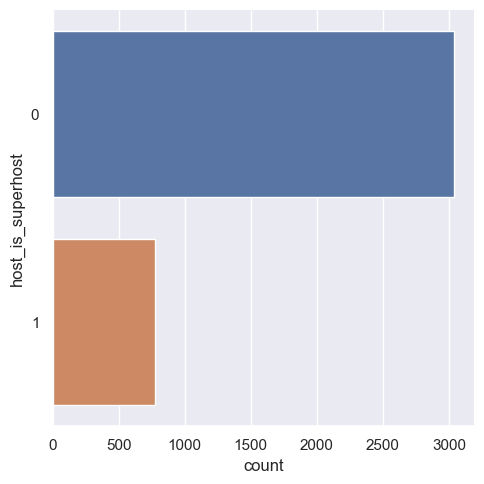

In [110]:
sb.catplot(y = "host_is_superhost", data = y, kind = "count")

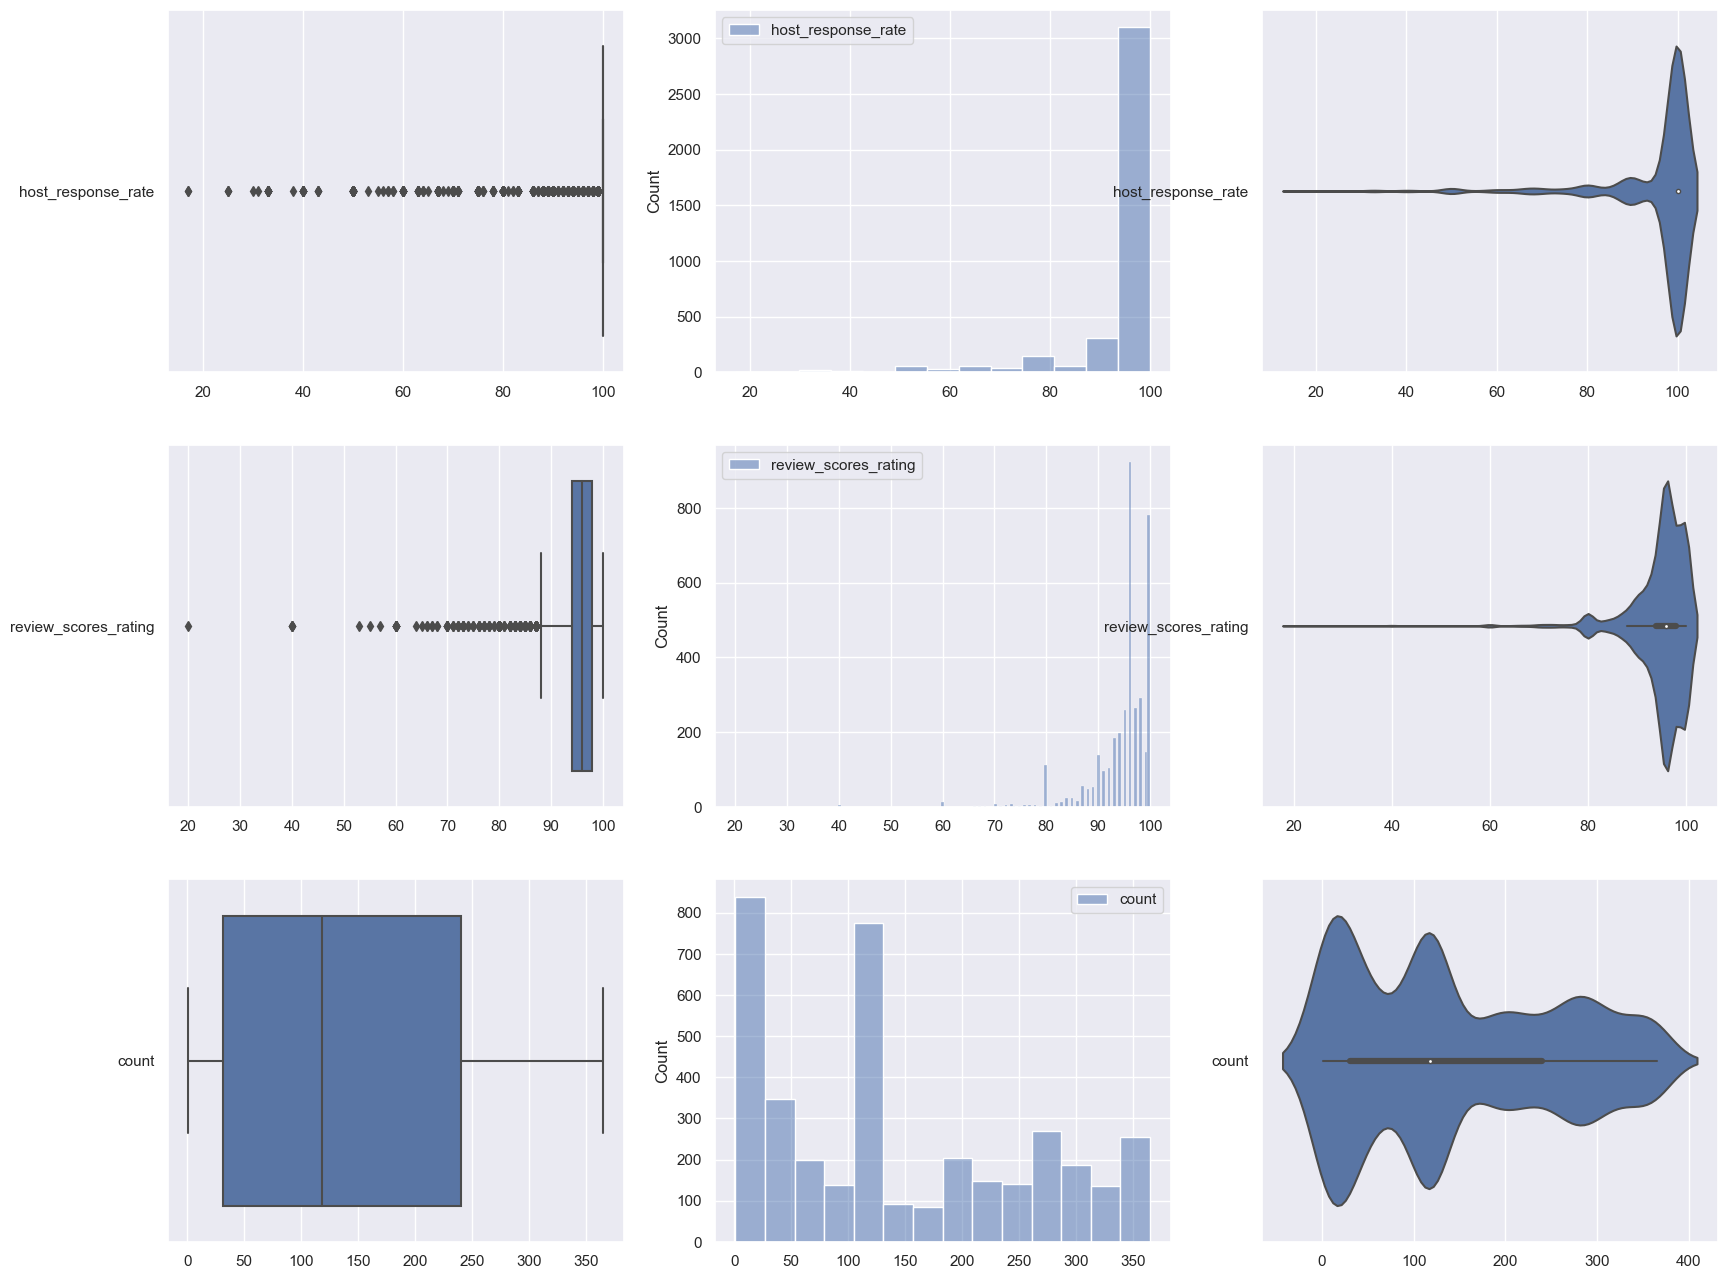

In [111]:
f, axes = plt.subplots(3, 3, figsize=(20, 16))
count = 0
for var in X:
    sb.boxplot(data = X[[var]], orient = "h", ax = axes[count,0])
    sb.histplot(data = X[[var]], ax = axes[count,1])
    sb.violinplot(data = X[[var]], orient = "h", ax = axes[count,2])
    count += 1

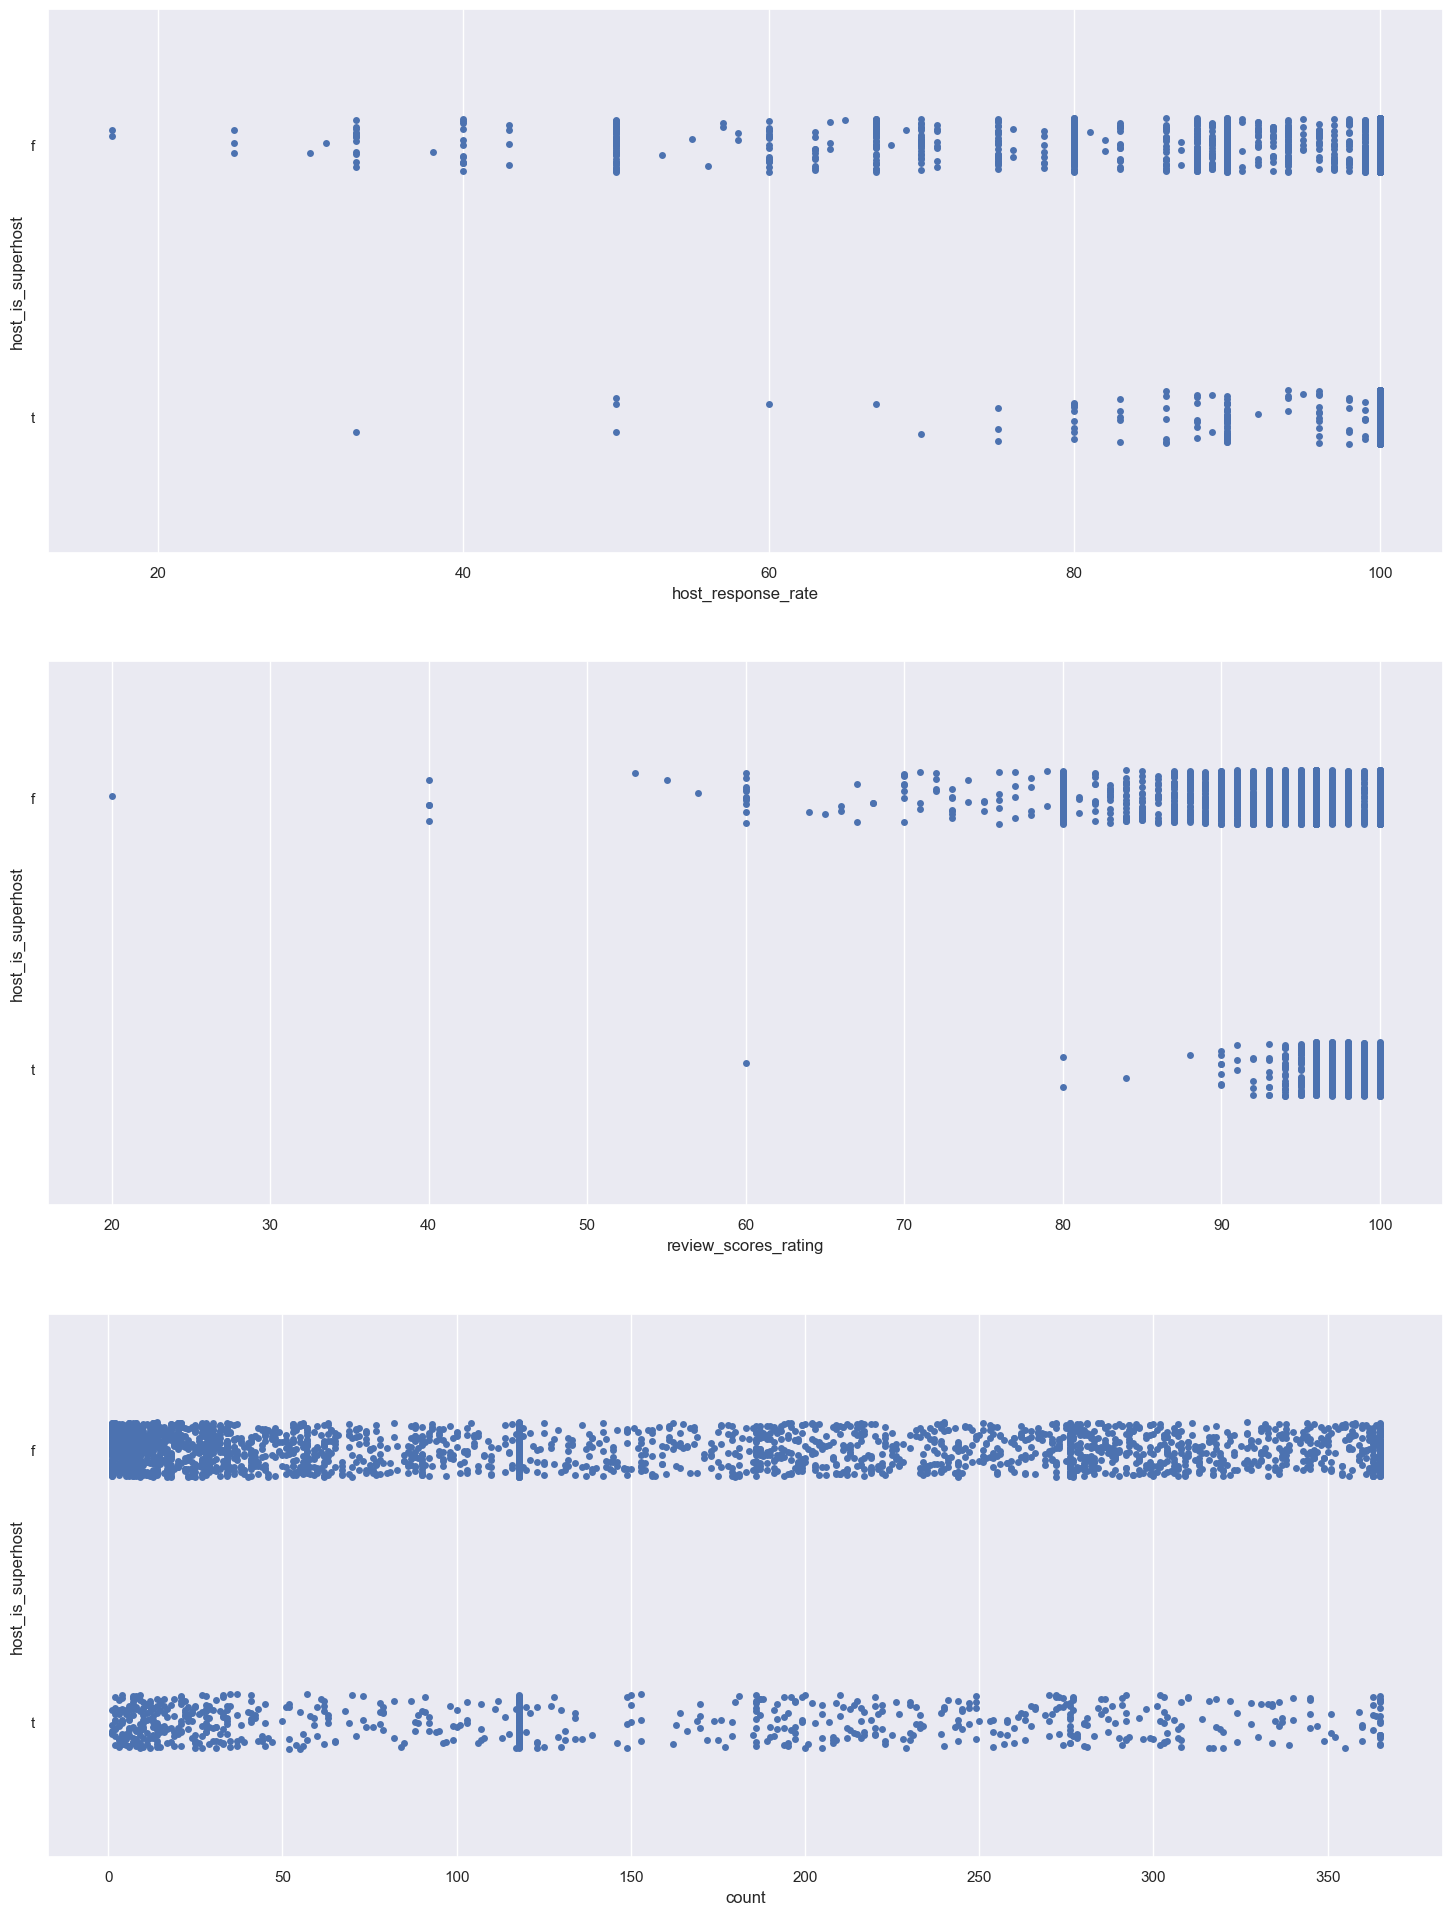

In [112]:
f, axes = plt.subplots(3, 1, figsize=(18, 24))

count = 0
for var in X:
    sb.stripplot(x = var, y = "host_is_superhost", data = joint_df_clean, orient = "h", ax = axes[count])
    count += 1

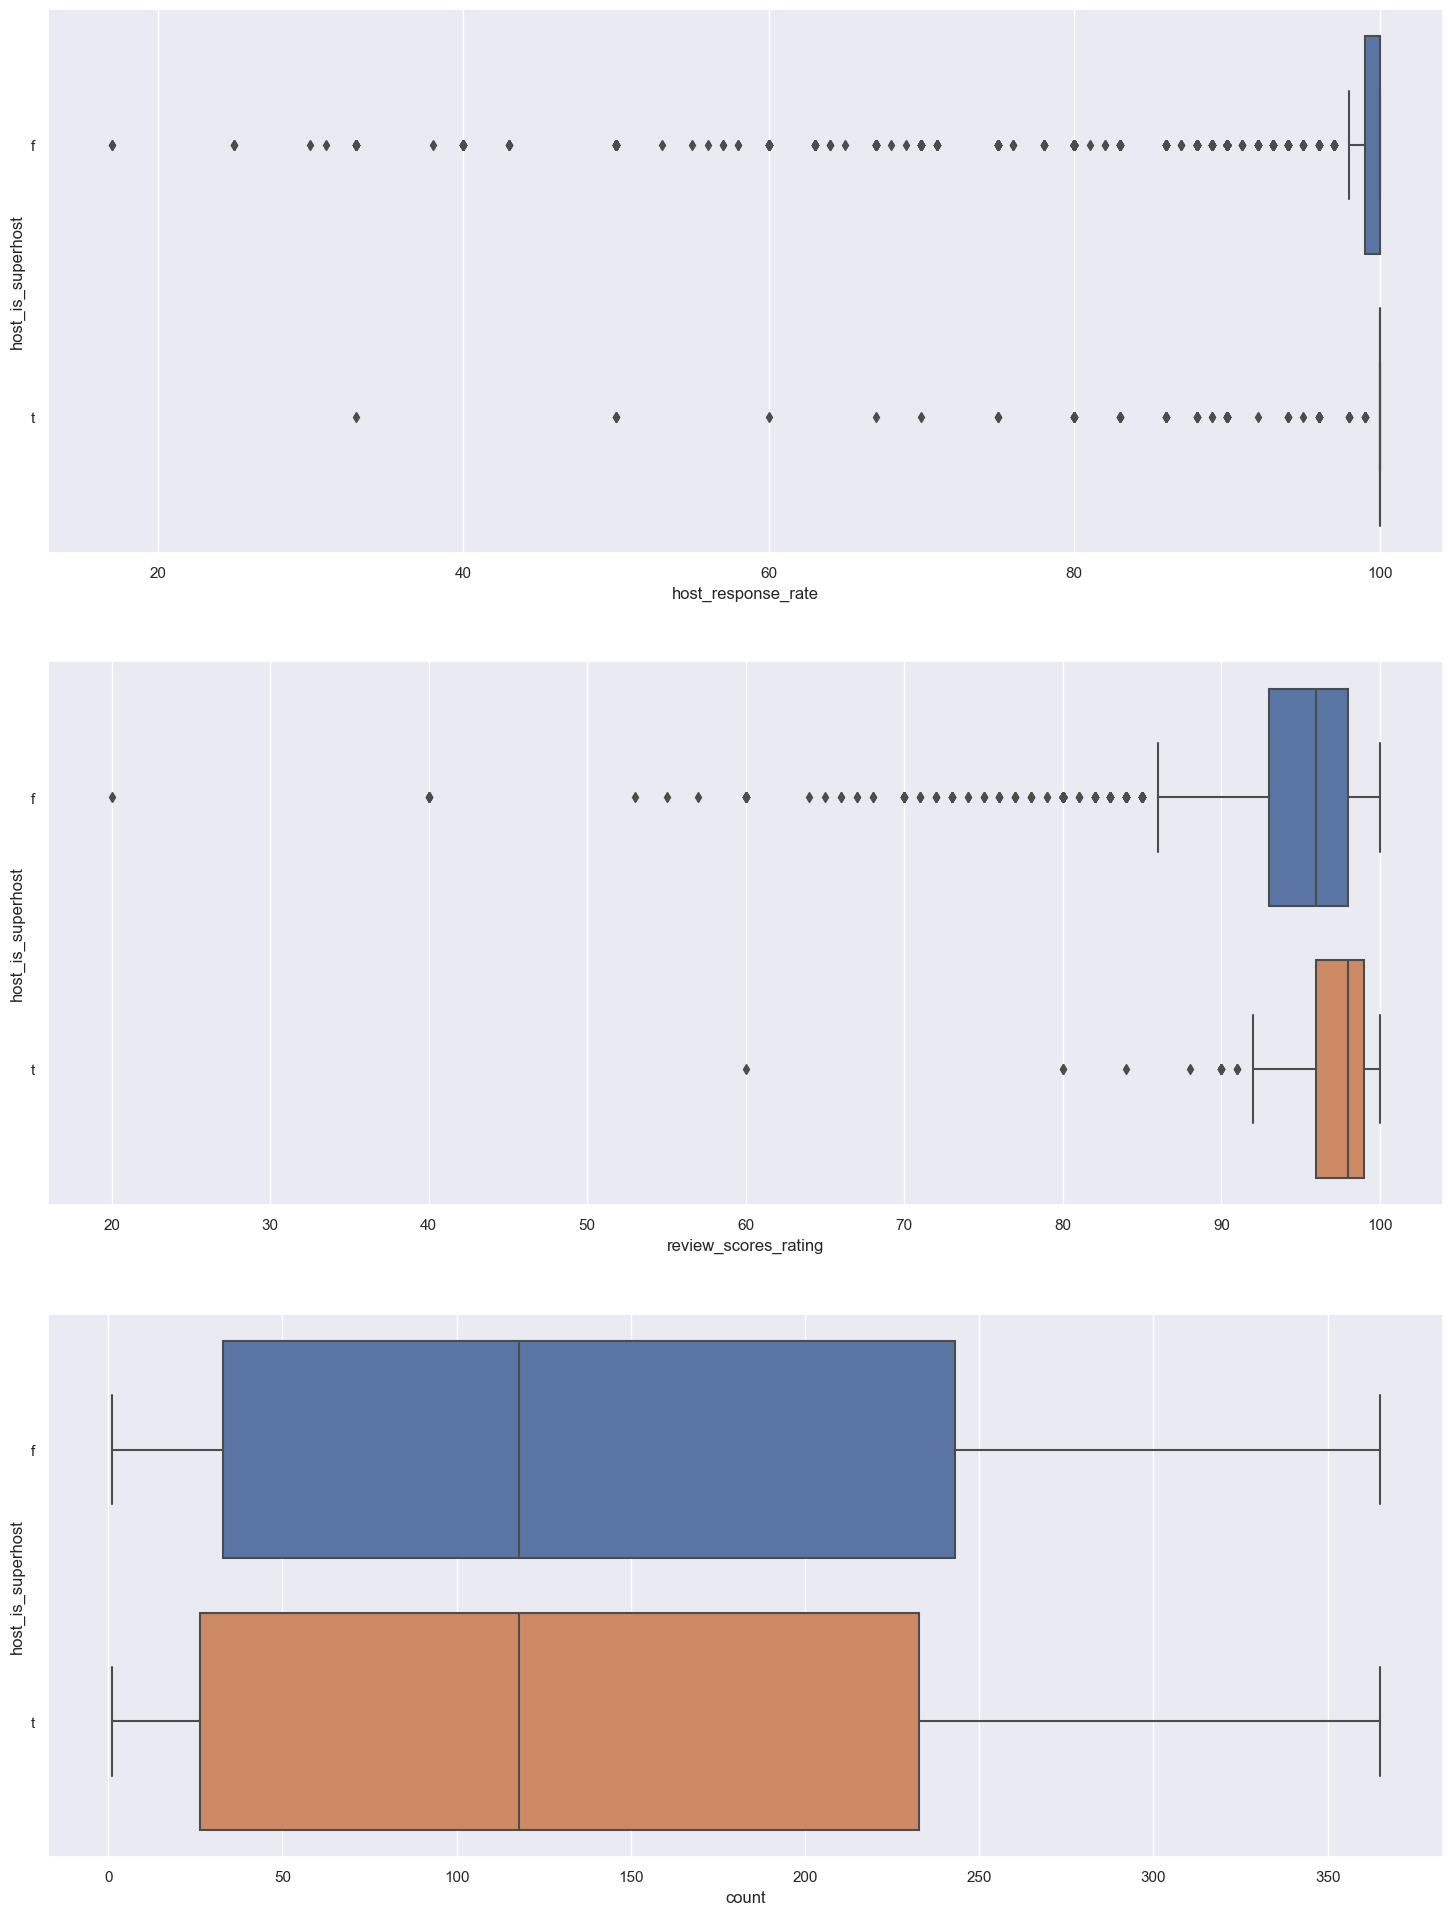

In [113]:
f, axes = plt.subplots(3, 1, figsize=(18, 24))

count = 0
for var in X:
    sb.boxplot(x = var, y = "host_is_superhost", data = joint_df_clean, orient = "h", ax = axes[count])
    count += 1

#### Building classification model

In [114]:
rf = RandomForestClassifier(n_estimators=400,max_features='log2',max_depth=10,criterion='gini',min_samples_leaf=35)
skf = StratifiedKFold(n_splits = 5,random_state=42,shuffle=True)
smote = SMOTE()

# List to store each fold's accuracy
accuracies_train = []
precisions_train = []
recalls_train = []
f1_train=[]

accuracies_test = []
precisions_test = []
recalls_test = []
f1_test=[]

for train_index, test_index in skf.split(X, y):
    X_train_temp, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train_temp, y_test = y.iloc[train_index], y.iloc[test_index]
    X_train, y_train = smote.fit_resample(X_train_temp, y_train_temp)

    # Train the model
    rf.fit(X_train, y_train.values.ravel())

    # Make predictions
    y_pred_train = rf.predict(X_train)
    y_pred_test = rf.predict(X_test)

    # Calculate accuraccy, precision and recall
    accuracy = accuracy_score(y_train, y_pred_train)
    accuracies_train.append(accuracy)
    precision = precision_score(y_train, y_pred_train)
    precisions_train.append(precision)
    recall = recall_score(y_train, y_pred_train)
    recalls_train.append(recall)
    f1 = f1_score(y_train, y_pred_train)
    f1_train.append(f1)
    
    
    accuracy = accuracy_score(y_test, y_pred_test)
    accuracies_test.append(accuracy)
    precision = precision_score(y_test, y_pred_test)
    precisions_test.append(precision)
    recall = recall_score(y_test, y_pred_test)
    recalls_test.append(recall)
    f1 = f1_score(y_test, y_pred_test)
    f1_test.append(f1)

# Calculate and print the average accuracy
average_accuracy_train = np.mean(accuracies_train)
average_accuracy_test = np.mean(accuracies_test)
print(f'Average train accuracy: {average_accuracy_train}')
print(f'Average test accuracy: {average_accuracy_test}')
print()
average_precision_train = np.mean(precisions_train)
average_precision_test = np.mean(precisions_test)
print(f'Average train precision: {average_precision_train}')
print(f'Average test precision: {average_precision_test}')
print()
average_recall_train = np.mean(recalls_train)
average_recall_test = np.mean(recalls_test)
print(f'Average train recall: {average_recall_train}')
print(f'Average test recall: {average_recall_test}')
print()
average_f1_train = np.mean(f1_train)
average_f1_test = np.mean(f1_test)
print(f'Average train f1: {average_f1_train}')
print(f'Average test f1: {average_f1_test}')

Average train accuracy: 0.8177258084447626
Average test accuracy: 0.8257278722046483

Average train precision: 0.8888109229394588
Average test precision: 0.5871755538270964

Average train recall: 0.7263836623313749
Average test recall: 0.5231513647642679

Average train f1: 0.7993724907462855
Average test f1: 0.5514072647500876


<Axes: >

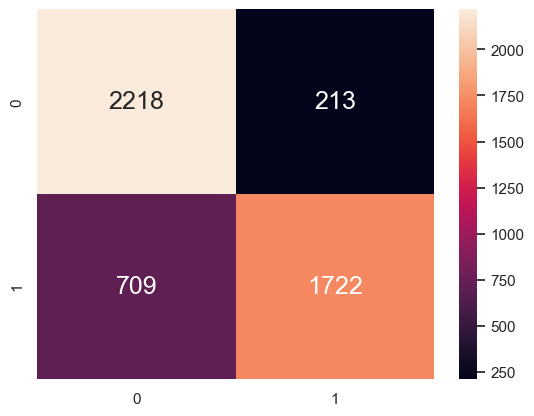

In [115]:
sb.heatmap(confusion_matrix(y_train, y_pred_train), 
           annot = True, fmt=".0f", annot_kws={"size": 18})

<Axes: >

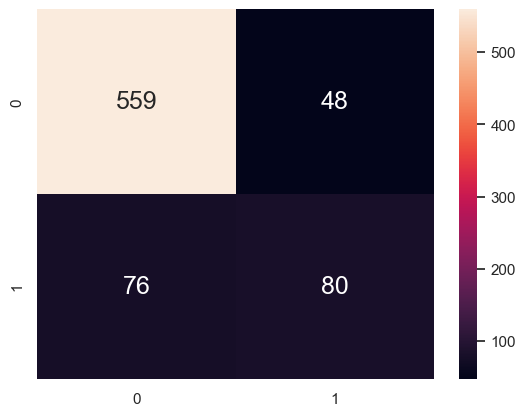

In [116]:
sb.heatmap(confusion_matrix(y_test, y_pred_test), 
           annot = True, fmt=".0f", annot_kws={"size": 18})

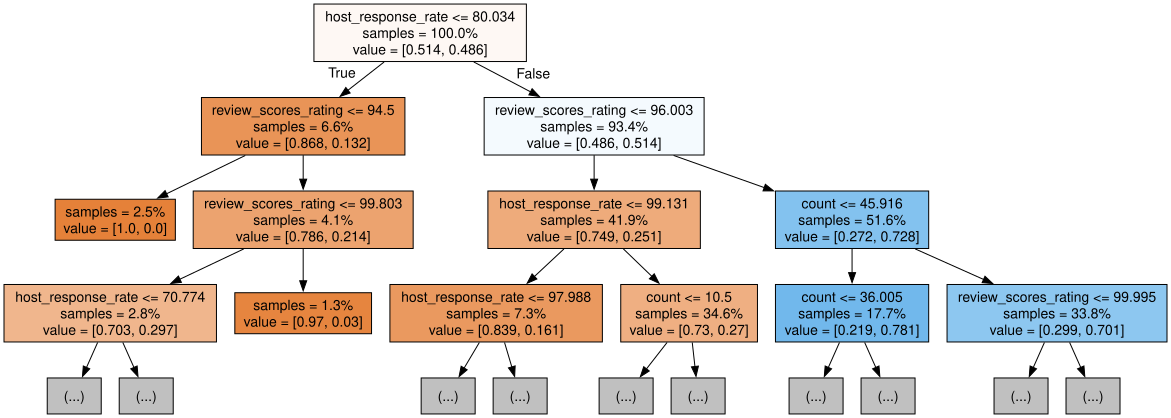

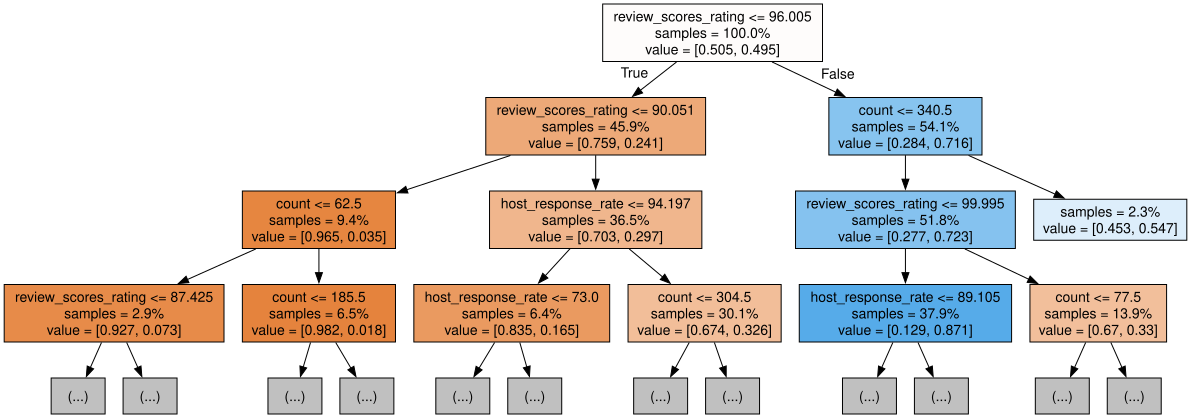

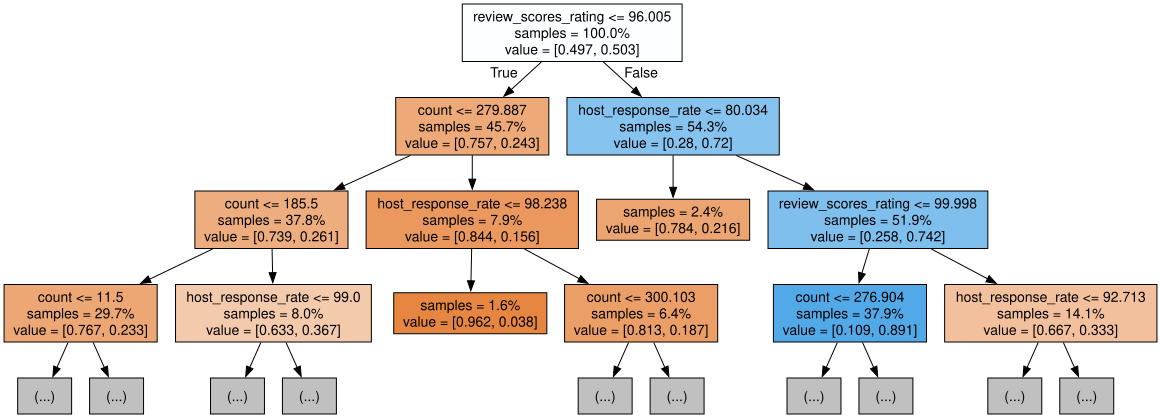

In [117]:
for i in range(3):
    tree = rf.estimators_[i]
    dot_data = export_graphviz(tree,
                               feature_names=X_train.columns,  
                               filled=True,  
                               max_depth=3, 
                               impurity=False, 
                               proportion=True)
    graph = graphviz.Source(dot_data)
    display(graph)

#### Hyperparameter tuning

In [20]:
param_grid = { 
    'n_estimators': [200,300,400,500,600],
    'max_features': ['sqrt', 'log2'],
    'max_depth' : [4,5,6,7,8,9,10],
    'criterion' :['gini', 'entropy','log_loss'],
    'min_samples_leaf' :[5,10,15,20,30]
}
start_time = time.time()
CV_rf = GridSearchCV(estimator=rf, param_grid=param_grid, cv= skf,n_jobs=-1)
CV_rf.fit(X_train, y_train.values.ravel())
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute: {elapsed_time:.3f} seconds")

Elapsed time to compute: 609.553 seconds


In [21]:
CV_rf.best_params_

{'criterion': 'gini',
 'max_depth': 10,
 'max_features': 'log2',
 'min_samples_leaf': 5,
 'n_estimators': 400}

#### Determining feature importances 

Text(0.5, 1.0, 'Permutation Feature Importance')

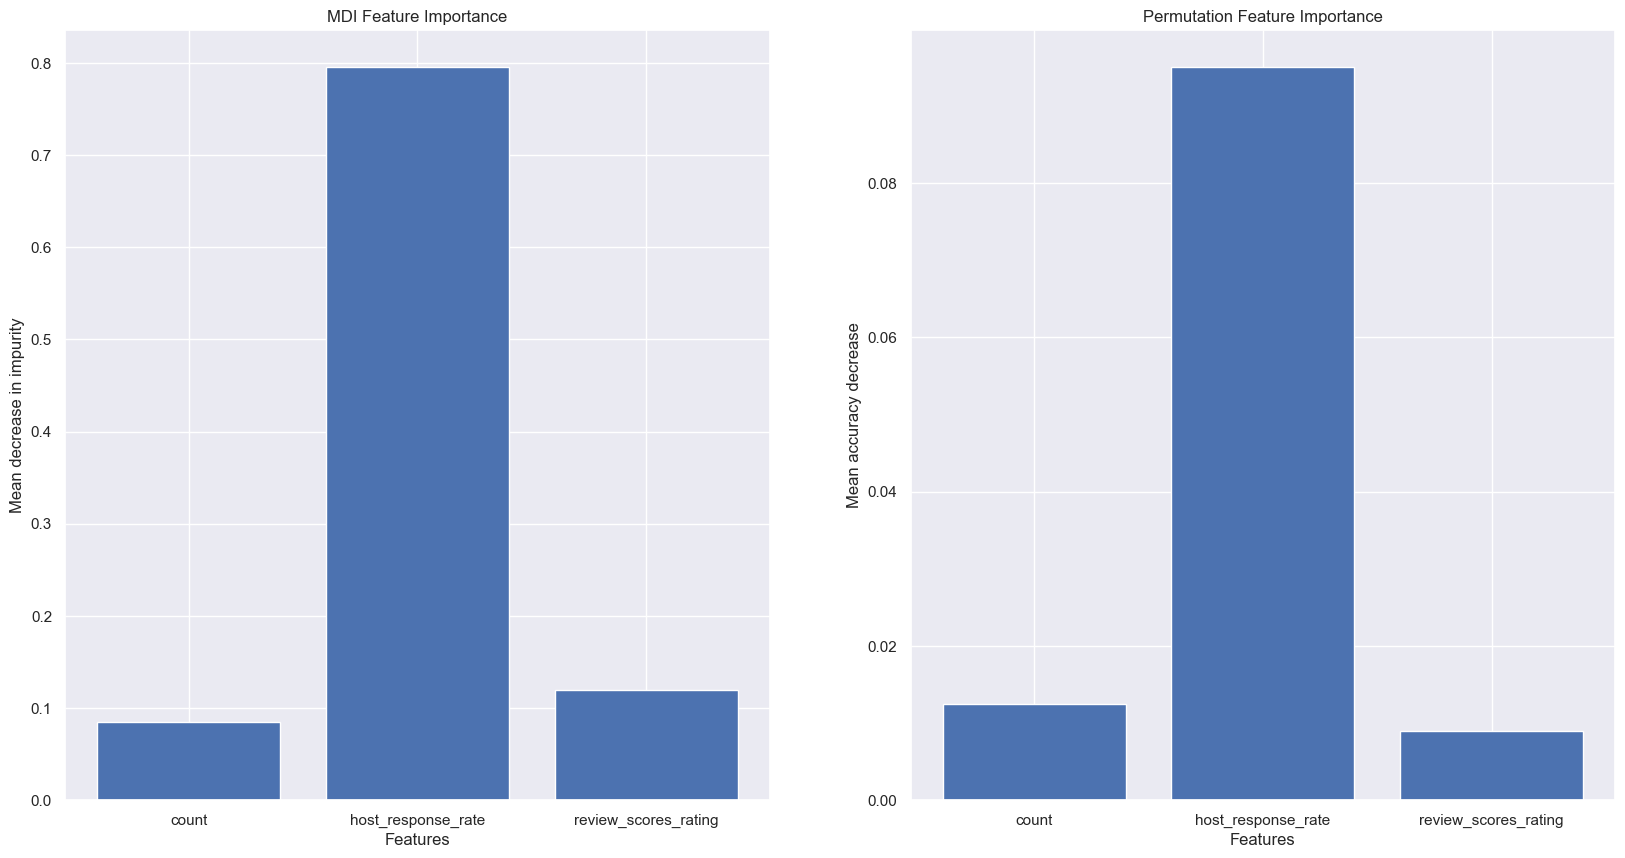

In [122]:
feature_names=["count","host_response_rate","review_scores_rating"]
feature_importances_mdi = np.zeros(X.shape[1])
feature_importances_permutation = np.zeros(X.shape[1])
for train_index, test_index in skf.split(X, y):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
   
    rf.fit(X_train, y_train.values.ravel())
    #using MDI
    feature_importances_mdi += rf.feature_importances_

    #using feature permutation
    result = permutation_importance(rf, X_train, y_train, n_repeats=10,
                                    random_state=42, n_jobs=-1)
    feature_importances_permutation += result.importances_mean

feature_importances_mdi /= skf.get_n_splits()
feature_importances_permutation /= skf.get_n_splits()

plt.figure(figsize=(20, 10))

plt.subplot(1, 2, 1)
plt.bar(feature_names, feature_importances_mdi)
plt.xlabel('Features')
plt.ylabel('Mean decrease in impurity')
plt.title('MDI Feature Importance')

plt.subplot(1, 2, 2)
plt.bar(feature_names, feature_importances_permutation)
plt.xlabel('Features')
plt.ylabel('Mean accuracy decrease')
plt.title('Permutation Feature Importance')


host_response_rate is the most important factor, followed likely by review_scores_rating and lastly, count.
In other words, host should prioritise improving their response rate, while improving their review scores and improving occupancy are secondary. 

#### Classification using different features

In [39]:
superhost_df_new=listings_csv[["host_is_superhost","host_response_rate","review_scores_rating","no_of_months_hosting","reviews_per_month"]]
superhost_df_new.index = listings_csv["id"]
superhost_df_new_clean=superhost_df_new.copy()
superhost_df_new_clean.dropna(subset=["host_is_superhost"],inplace=True)
superhost_df_new_clean["host_response_rate"] = superhost_df_new_clean["host_response_rate"].str.replace("%","")
superhost_df_new_clean["host_response_rate"]=pd.to_numeric(superhost_df_new_clean["host_response_rate"])
superhost_df_new_clean["host_response_rate"].fillna(superhost_df_new_clean["host_response_rate"].median(),inplace=True) 
superhost_df_new_clean["review_scores_rating"].fillna(superhost_df_new_clean["review_scores_rating"].median(),inplace=True)
superhost_df_new_clean["reviews_per_month"].fillna(superhost_df_new_clean["reviews_per_month"].median(),inplace=True)
y_new=pd.DataFrame(superhost_df_new_clean["host_is_superhost"])
y_new=y_new.replace(to_replace="t",value=1)
y_new=y_new.replace(to_replace="f",value=0)
X_new=superhost_df_new_clean.drop(["host_is_superhost"],axis=1)

In [40]:
superhost_df_new_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3816 entries, 241032 to 10208623
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   host_is_superhost     3816 non-null   object 
 1   host_response_rate    3816 non-null   float64
 2   review_scores_rating  3816 non-null   float64
 3   no_of_months_hosting  3816 non-null   int64  
 4   reviews_per_month     3816 non-null   float64
dtypes: float64(3), int64(1), object(1)
memory usage: 178.9+ KB


In [41]:
superhost_df_new.head(10)

,host_is_superhost,host_response_rate,review_scores_rating,no_of_months_hosting,reviews_per_month
id,,,,,
241032,f,96%,95.0,52,4.07
953595,t,98%,96.0,34,1.48
3308979,f,67%,97.0,18,1.15
7421966,f,NaN,NaN,25,NaN
278830,f,100%,92.0,49,0.89
5956968,f,NaN,95.0,60,2.45
1909058,t,100%,99.0,43,2.46
856550,t,100%,97.0,38,4.73
4948745,f,NaN,97.0,44,1.22


In [42]:
X_new.head(10)

,host_response_rate,review_scores_rating,no_of_months_hosting,reviews_per_month
id,,,,
241032,96.0,95.0,52,4.07
953595,98.0,96.0,34,1.48
3308979,67.0,97.0,18,1.15
7421966,100.0,96.0,25,1.54
278830,100.0,92.0,49,0.89
5956968,100.0,95.0,60,2.45
1909058,100.0,99.0,43,2.46
856550,100.0,97.0,38,4.73
4948745,100.0,97.0,44,1.22


In [43]:
y_new.head(10)

,host_is_superhost
id,
241032,0
953595,1
3308979,0
7421966,0
278830,0
5956968,0
1909058,1
856550,1
4948745,0


In [44]:
X_new.describe()

,host_response_rate,review_scores_rating,no_of_months_hosting,reviews_per_month
count,3816.000000,3816.000000,3816.000000,3816.000000
mean,95.584906,94.786164,27.021488,1.990653
std,11.165601,6.046641,18.729293,1.678296
min,17.000000,20.000000,0.000000,0.020000
25%,100.000000,94.000000,11.000000,0.830000
50%,100.000000,96.000000,24.000000,1.540000
75%,100.000000,98.000000,40.000000,2.660000
max,100.000000,100.000000,85.000000,12.150000


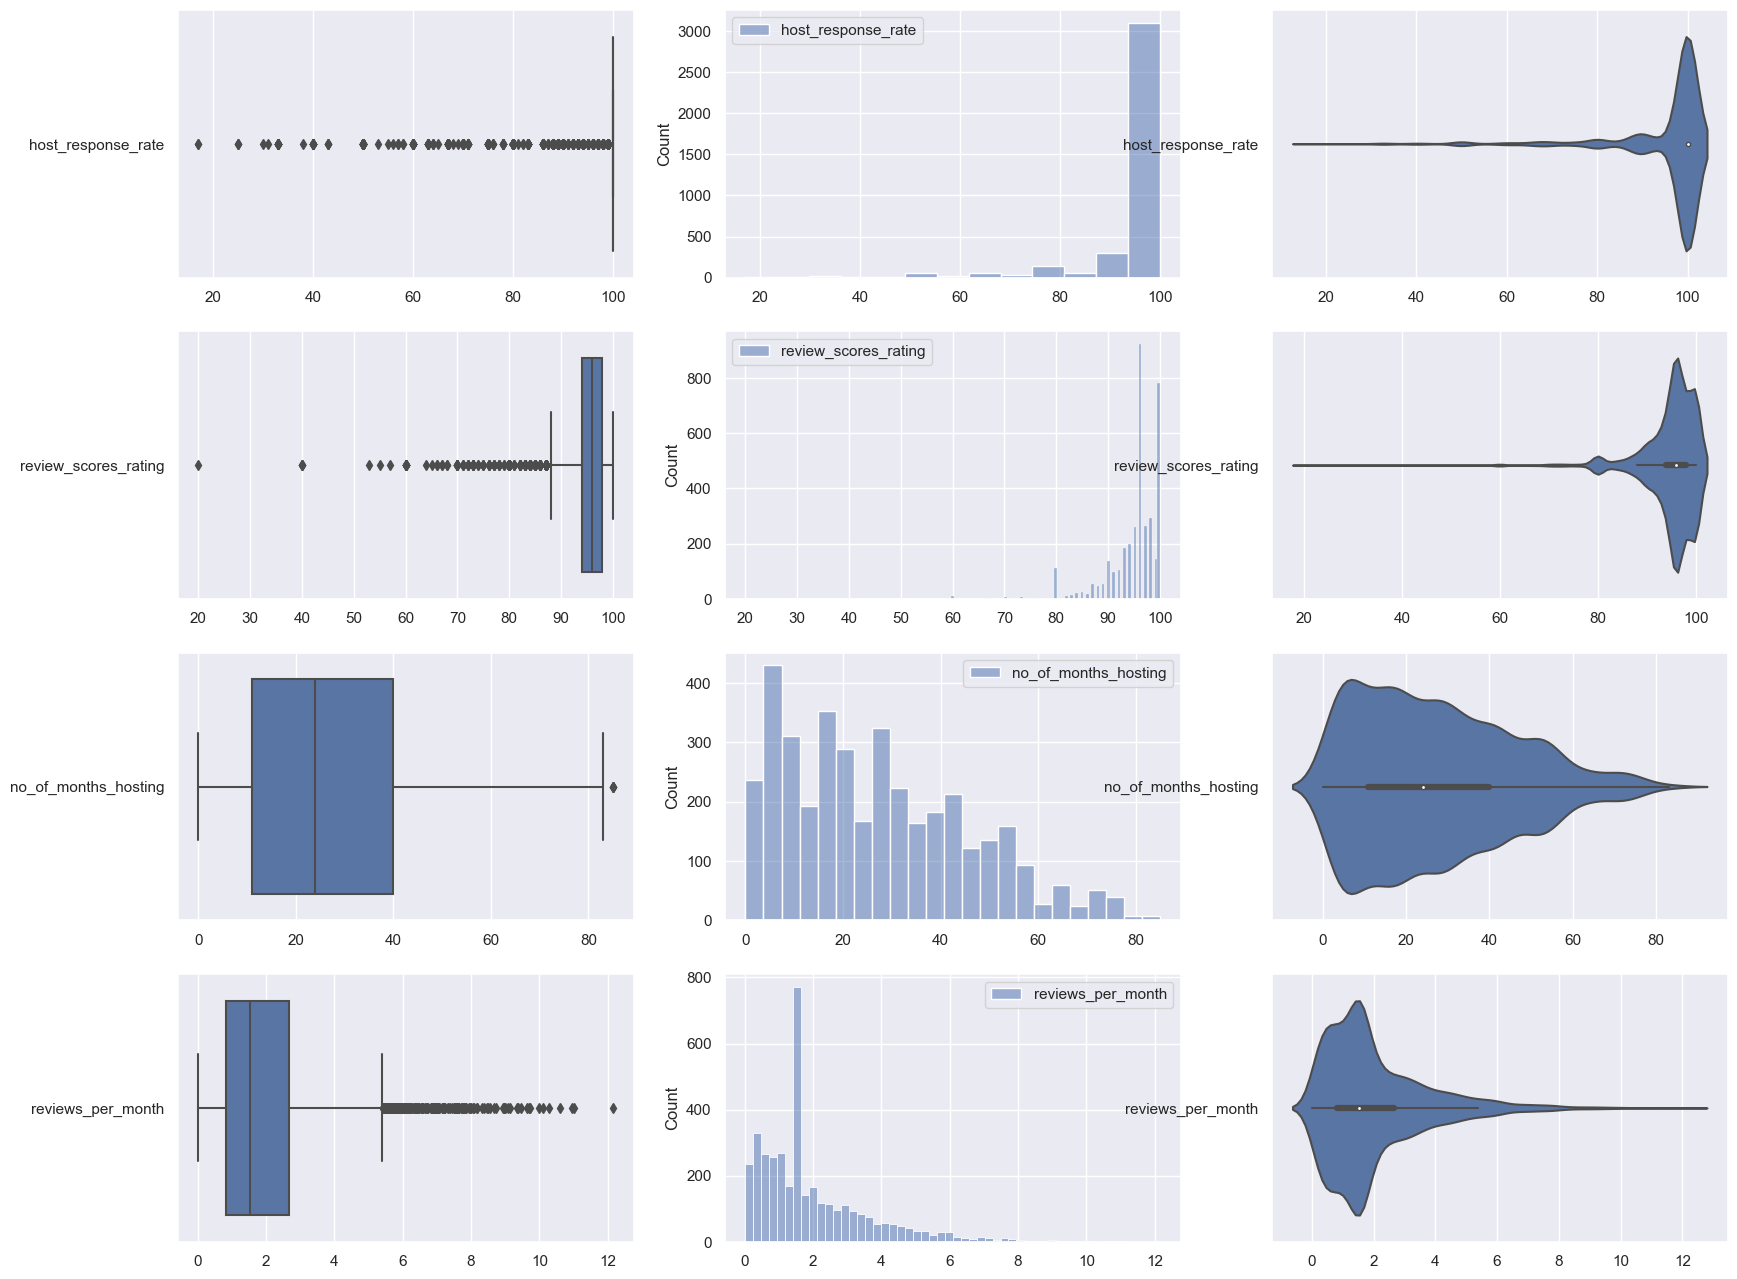

In [45]:
f, axes = plt.subplots(4, 3, figsize=(20, 16))
count = 0
for var in X_new:
    sb.boxplot(data = X_new[[var]], orient = "h", ax = axes[count,0])
    sb.histplot(data = X_new[[var]], ax = axes[count,1])
    sb.violinplot(data = X_new[[var]], orient = "h", ax = axes[count,2])
    count += 1

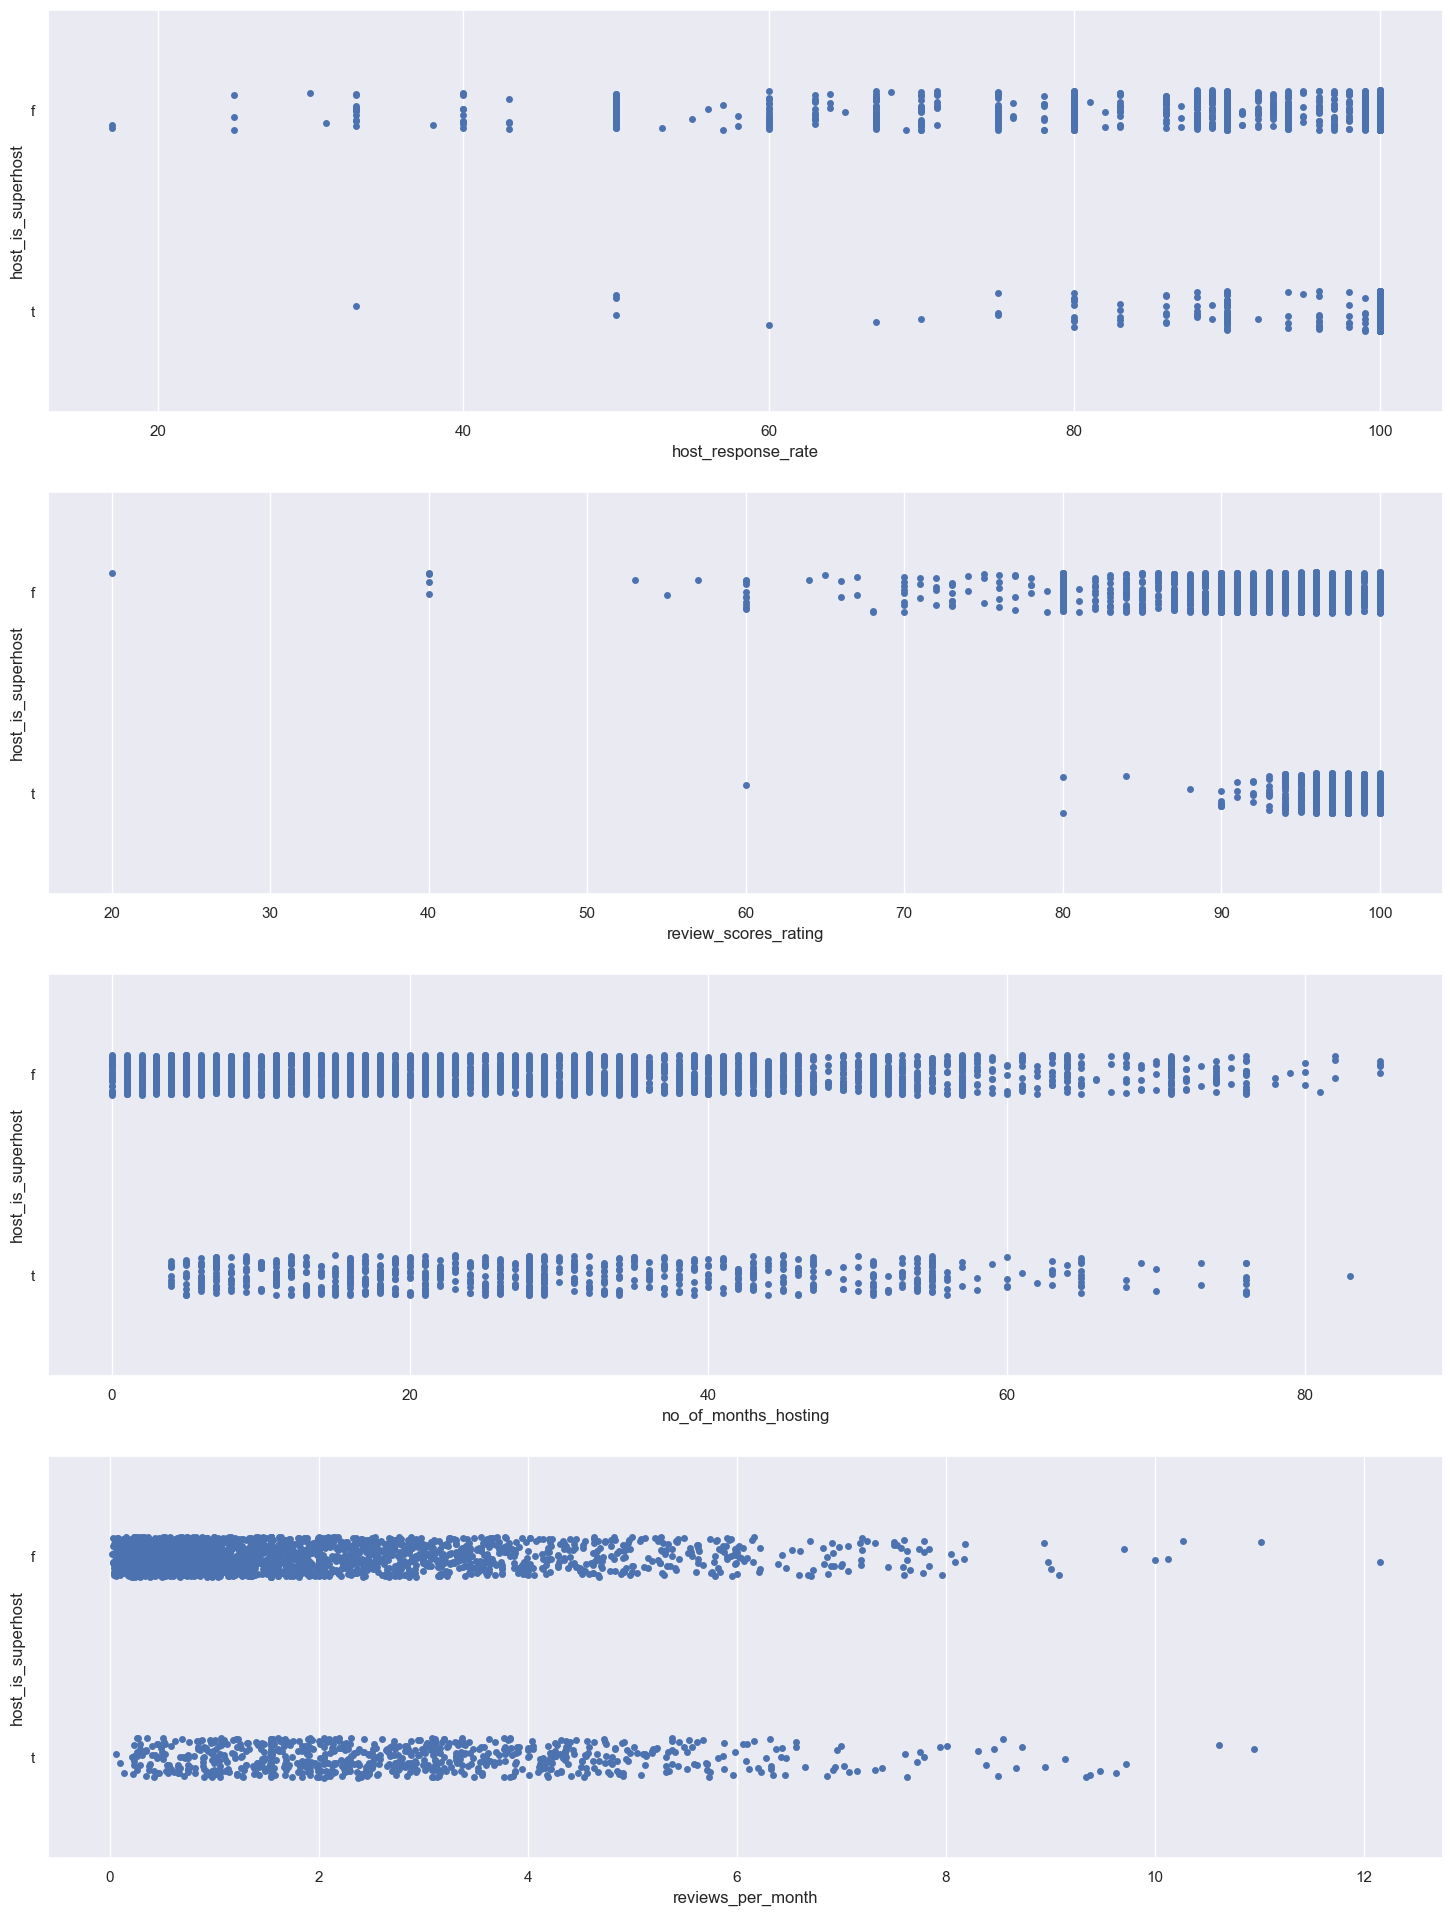

In [46]:
f, axes = plt.subplots(4, 1, figsize=(18, 24))

count = 0
for var in X_new:
    sb.stripplot(x = var, y = "host_is_superhost", data = superhost_df_new_clean, orient = "h", ax = axes[count])
    count += 1

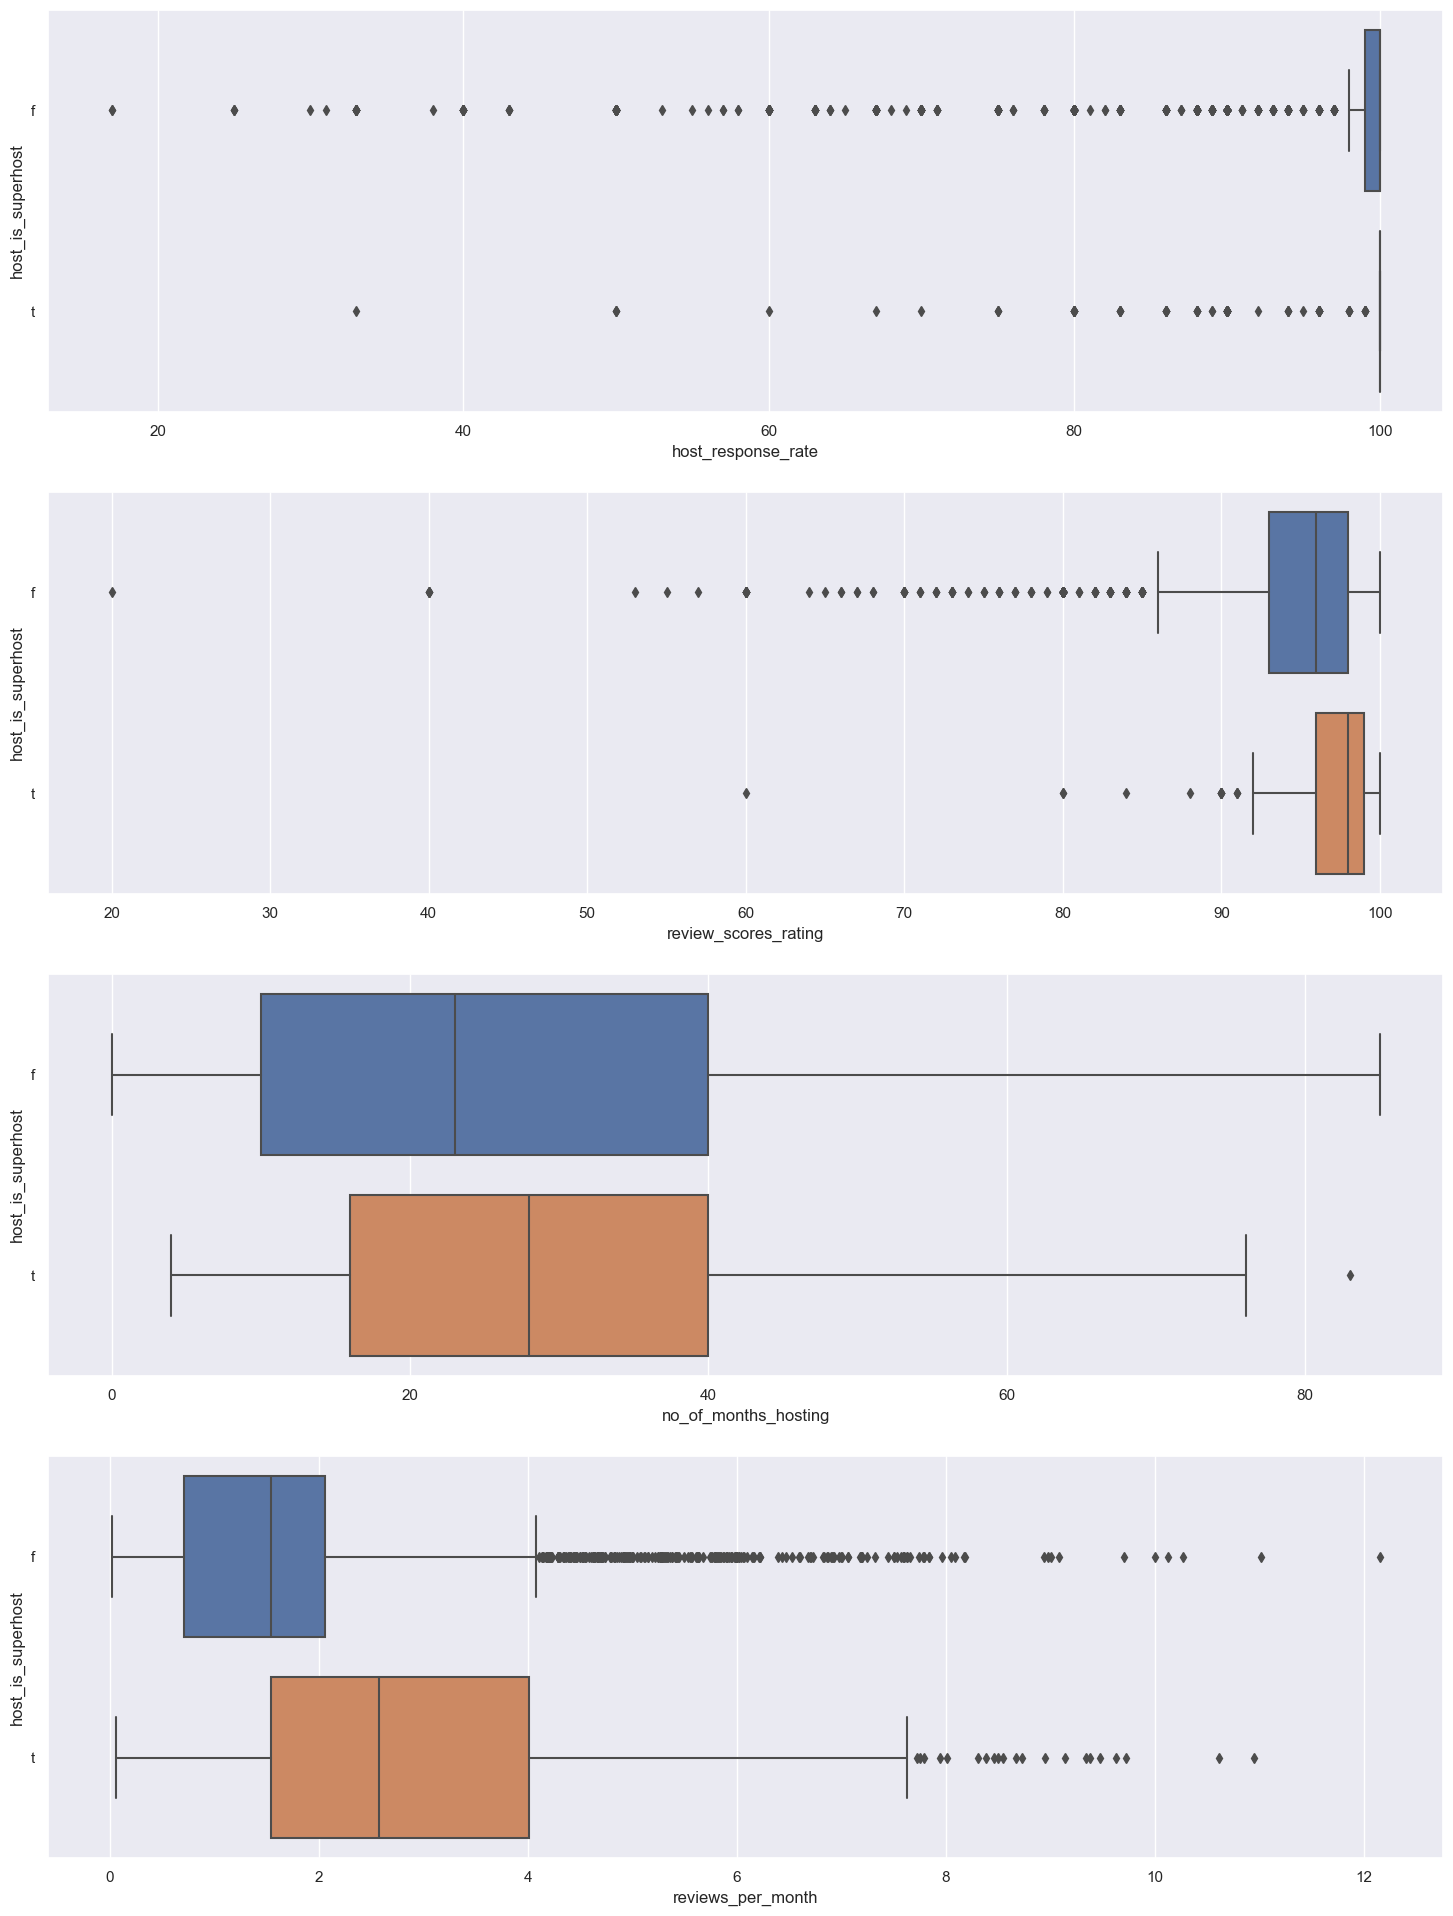

In [47]:
f, axes = plt.subplots(4, 1, figsize=(18, 24))

count = 0
for var in X_new:
    sb.boxplot(x = var, y = "host_is_superhost", data = superhost_df_new_clean, orient = "h", ax = axes[count])
    count += 1

In [123]:
rf_new = RandomForestClassifier(n_estimators=300,max_features='log2',max_depth=10,criterion='log_loss',min_samples_leaf=35)

accuracies_train = []
precisions_train = []
recalls_train = []
f1_train=[]

accuracies_test = []
precisions_test = []
recalls_test = []
f1_test=[]

for train_index, test_index in skf.split(X, y):
    X_train_new_temp, X_test_new = X_new.iloc[train_index], X_new.iloc[test_index]
    y_train_new_temp, y_test_new = y_new.iloc[train_index], y_new.iloc[test_index]
    X_train_new, y_train_new = smote.fit_resample(X_train_new_temp, y_train_new_temp)
    #X_train_new, y_train_new = tl.fit_resample(X_train_new_temp, y_train_new_temp)

    # Train the model
    rf_new.fit(X_train_new, y_train_new.values.ravel())

    # Make predictions
    y_pred_train = rf_new.predict(X_train_new)
    y_pred_test = rf_new.predict(X_test_new)

    # Calculate accuraccy, precision and recall
    accuracy = accuracy_score(y_train_new, y_pred_train)
    accuracies_train.append(accuracy)
    precision = precision_score(y_train_new, y_pred_train)
    precisions_train.append(precision)
    recall = recall_score(y_train_new, y_pred_train)
    recalls_train.append(recall)
    f1 = f1_score(y_train_new, y_pred_train)
    f1_train.append(f1)
    
    
    accuracy = accuracy_score(y_test_new, y_pred_test)
    accuracies_test.append(accuracy)
    precision = precision_score(y_test_new, y_pred_test)
    precisions_test.append(precision)
    recall = recall_score(y_test_new, y_pred_test)
    recalls_test.append(recall)
    f1 = f1_score(y_test_new, y_pred_test)
    f1_test.append(f1)

# Calculate and print the average accuracy
average_accuracy_train = np.mean(accuracies_train)
average_accuracy_test = np.mean(accuracies_test)
print(f'Average train accuracy: {average_accuracy_train}')
print(f'Average test accuracy: {average_accuracy_test}')
print()
average_precision_train = np.mean(precisions_train)
average_precision_test = np.mean(precisions_test)
print(f'Average train precision: {average_precision_train}')
print(f'Average test precision: {average_precision_test}')
print()
average_recall_train = np.mean(recalls_train)
average_recall_test = np.mean(recalls_test)
print(f'Average train recall: {average_recall_train}')
print(f'Average test recall: {average_recall_test}')
print()
average_f1_train = np.mean(f1_train)
average_f1_test = np.mean(f1_test)
print(f'Average train f1: {average_f1_train}')
print(f'Average test f1: {average_f1_test}')

Average train accuracy: 0.8514949434248364
Average test accuracy: 0.8131603686193243

Average train precision: 0.848914986688662
Average test precision: 0.529633603487704

Average train recall: 0.8555414777259468
Average test recall: 0.7228339602520013

Average train f1: 0.8520805106210652
Average test f1: 0.6109047035680852


Including more features heped to improve accuracy and F1 score

<Axes: >

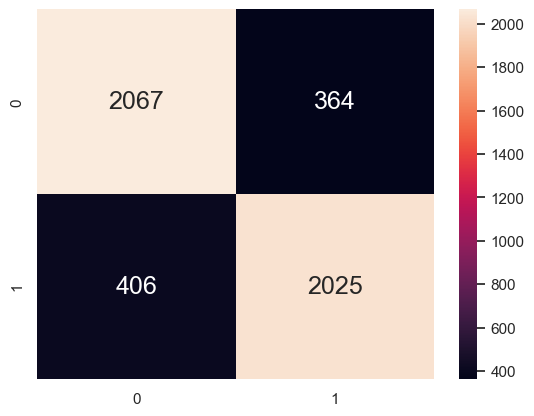

In [60]:
sb.heatmap(confusion_matrix(y_train_new, y_pred_train), 
           annot = True, fmt=".0f", annot_kws={"size": 18})

<Axes: >

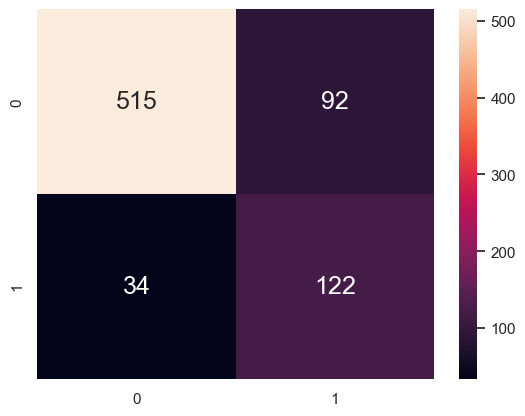

In [61]:
sb.heatmap(confusion_matrix(y_test_new, y_pred_test), 
           annot = True, fmt=".0f", annot_kws={"size": 18})

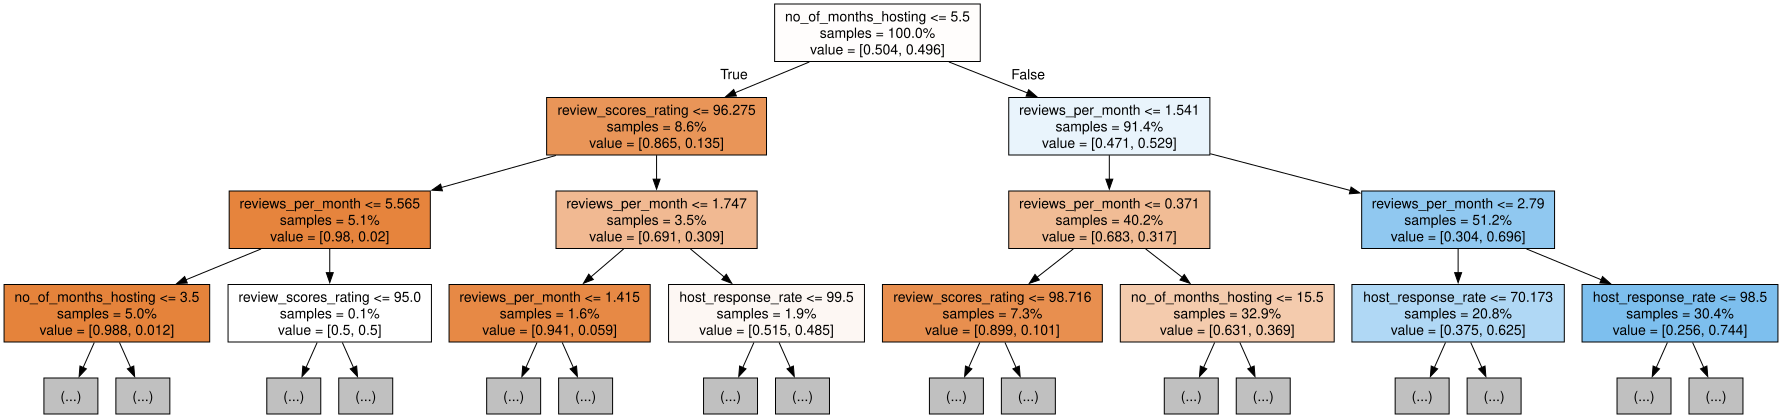

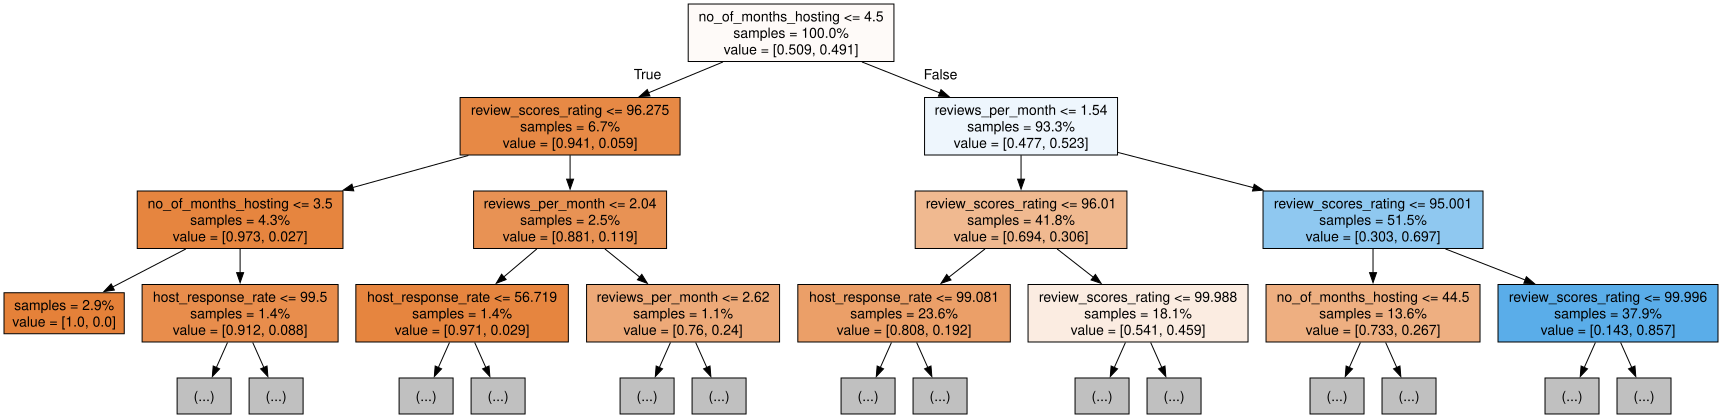

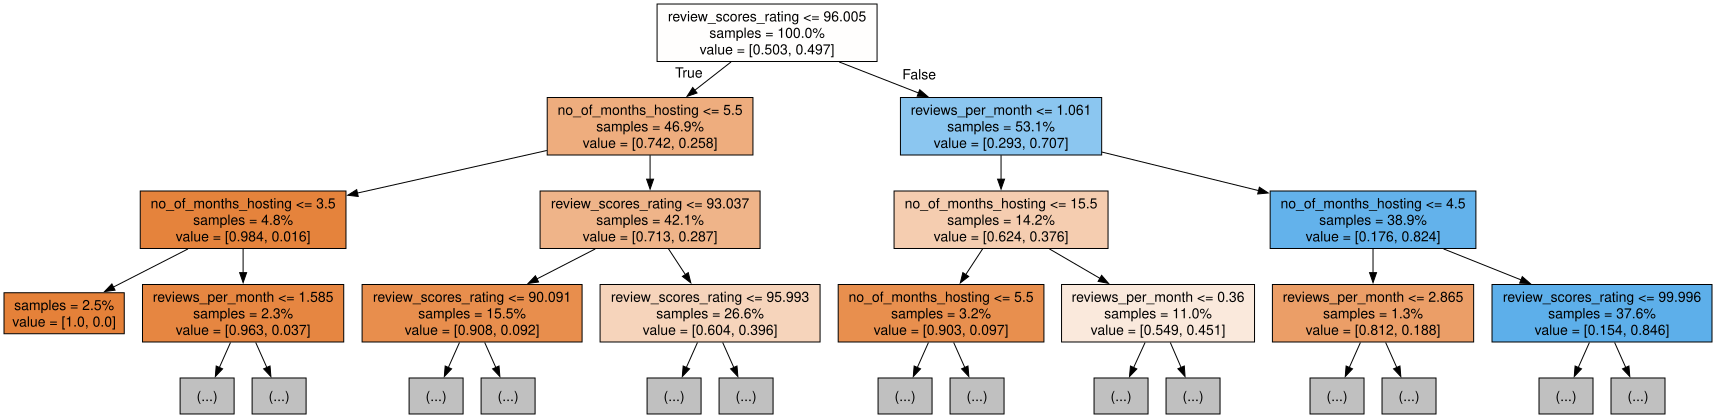

In [87]:
for i in range(3):
    tree = rf_new.estimators_[i]
    dot_data = export_graphviz(tree,
                               feature_names=X_train_new.columns,  
                               filled=True,  
                               max_depth=3, 
                               impurity=False, 
                               proportion=True)
    graph = graphviz.Source(dot_data)
    display(graph)

In [94]:
param_grid = { 
    'n_estimators': [200,300,400,500,600],
    'max_features': ['sqrt', 'log2'],
    'max_depth' : [4,5,6,7,8,9,10],
    'criterion' :['gini', 'entropy','log_loss'],
    'min_samples_leaf' :[5,10,15,20,30]
}
start_time = time.time()
CV_rf_new = GridSearchCV(estimator=rf, param_grid=param_grid, cv= skf,n_jobs=-1)
CV_rf_new.fit(X_train_new, y_train_new.values.ravel())
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute: {elapsed_time:.3f} seconds")

Elapsed time to compute: 1077.711 seconds


In [95]:
CV_rf_new.best_params_

{'criterion': 'log_loss',
 'max_depth': 10,
 'max_features': 'log2',
 'min_samples_leaf': 5,
 'n_estimators': 300}